In [1]:
# importation des modules
import pandas as pd
import missingno as msno
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
def fix(l):
    # 10 champs → on recolle la virgule au bon endroit
    if l[7].strip() == 'Environment':
        return l[:7] + [l[7] + ',' + l[8], l[9]]   # Division
    return l[:8] + [l[8] + ',' + l[9]]             # Section

df = pd.read_csv('SR2026.csv', encoding='latin-1',
                 engine='python', on_bad_lines=fix)

**Lorsqu'on charge le fichier normalement, on trouve deux problème.**

**1 : (ParserError: Error tokenizing data. C error: Expected 9 fields in line 36, saw 10)**
Des virgules non échappées dans certaines valeurs. Il y a 40 600 lignes sur 469 724 qui ont 10 champs au lieu de 9, parce que certaines valeurs contiennent une virgule mais ne sont pas entre guillemets :
Environment, Climate & Forestry (colonne Division) : 40 580 lignes
Transfer, Disposal & Operations (colonne Section) : 20 lignes

**2 : UnicodeDecodeError: 'utf-8' codec can't decode byte 0xe9 in position 152318: invalid continuation byte**
L'encodage n'est pas en UTF-8. Il y a des caractères comme é en Latin-1. Une fois la première erreur corrigée, vous auriez eu une UnicodeDecodeError.

**On crée une fonction nommée fix. Pandas l'appellera à chaque fois qu'il trouve une ligne cassée, c'est-à-dire une ligne qui a 10 morceaux au lieu de 9**

In [3]:
# information du dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 469724 entries, 0 to 469723
Data columns (total 9 columns):
 #   Column                        Non-Null Count   Dtype 
---  ------                        --------------   ----- 
 0   Creation Date                 469724 non-null  object
 1   Status                        469724 non-null  object
 2   First 3 Chars of Postal Code  469724 non-null  object
 3   Intersection Street 1         89922 non-null   object
 4   Intersection Street 2         89216 non-null   object
 5   Ward                          469724 non-null  object
 6   Service Request Type          469716 non-null  object
 7   Division                      469724 non-null  object
 8   Section                       469724 non-null  object
dtypes: object(9)
memory usage: 32.3+ MB


In [4]:
# Affichage d'un echantillon
df.sample(5)

,Creation Date,Status,First 3 Chars of Postal Code,Intersection Street 1,Intersection Street 2,Ward,Service Request Type,Division,Section
106189,2026-03-02 10:45:26.0000000,Cancelled,Intersection,Prince Edward Dr N,Government Rd,Etobicoke-Lakeshore (03),Road Pothole / Road Damage,Transportation Services,Road Operations
364076,2026-08-19 16:00:15.0000000,Completed,M4C,NaN,NaN,Beaches-East York (19),Graffiti on Private Property,Municipal Licensing & Standards,Investigation Services
314561,2026-07-17 08:42:12.0000000,New,M4L,NaN,NaN,Toronto-Danforth (14),General Pruning,"Environment, Climate & Forestry",Forestry Operations
102123,2026-02-26 17:43:57.0000000,Cancelled,M4J,NaN,NaN,Toronto-Danforth (14),Animal Noise,Municipal Licensing & Standards,Toronto Animal Services
454398,2026-10-19 16:13:41.0000000,Completed,M2R,NaN,NaN,York Centre (06),Stationary Motor Vehicle Noise,Municipal Licensing & Standards,Bylaw Enforcement


**Notre dataset concerne le service 311 Toronto, qui permet aux résidents, aux entreprises et aux visiteurs d'accéder 24 heures sur 24, 7 jours sur 7, aux services municipaux non urgents, aux programmes et aux renseignements de la Ville de Toronto.**

**Le dataset comprend 469 724 demandes de service créées entre le 1er janvier et le 31 octobre 2026, réparties sur 9 colonnes. Voici le détail de chaque variable.**

**1. Creation Date : date et heure de création d'une demande de service (SR) et de sa transmission au système de gestion des tâches de la division responsable. Format : AAAA-MM-JJ HH:MM:SS.0000000. Pandas la lit comme du texte ; il faut la convertir avec pd.to_datetime(). Aucune valeur manquante.**

**2. Status : statut actuel de la demande. Le fichier contient 6 valeurs :**

**Completed (352 790) : la division a terminé l'intervention demandée.
Cancelled (44 243) : la demande a été annulée. Raisons possibles : la communication a été coupée, le client ne souhaitait pas créer de demande, le client a rappelé pour l'annuler, ou la demande a été créée par erreur.
In Progress (34 667) : la division travaille actuellement à résoudre la demande.
New (22 048) : la demande a été reçue et transmise à la division compétente, mais son traitement n'a pas encore commencé.
Closed (9 211) : la division a examiné la demande et pris les mesures nécessaires pour y répondre.
Unknown (6 765) : le statut n'est pas renseigné.**

**3. First 3 Chars of Postal Code : les 3 premiers caractères du code postal de l'adresse de la demande (la région de tri d'acheminement, ex. M6H). On n'utilise que 3 caractères pour protéger la vie privée. Quand la demande vise une intersection, la colonne contient le mot Intersection au lieu d'un code (89 922 lignes). On trouve 100 codes postaux distincts en plus de Intersection.**

**4. Intersection Street 1 : première rue de l'intersection où se situe la demande. Elle est remplie seulement quand la colonne 3 vaut Intersection et vide pour les autres lignes (379 802 valeurs manquantes).**

**5. Intersection Street 2 : deuxième rue de l'intersection. Même logique que la colonne 4, avec 380 508 valeurs manquantes. Dans 706 cas, la colonne 3 vaut Intersection mais la deuxième rue est absente.**

**6. Ward : quartier électoral (ward) municipal de la demande, avec son numéro entre parenthèses, ex. Scarborough North (23). On trouve 25 wards plus la valeur Unknown (13 lignes).**

**7. Service Request Type : le type précis de demande, ex. Road Pothole / Road Damage, Residential Bin Lid Damaged. Il y a 576 types distincts et 8 valeurs manquantes. Le type le plus fréquent est Road Pothole / Road Damage (25 033).**

**8. Division : la division municipale responsable de la demande. Il y a 7 valeurs : les 6 divisions officielles (Transportation Services, Solid Waste Management Services, Municipal Licensing & Standards, Environment, Climate & Forestry, Toronto Water, Parks and Recreation) et la valeur 311 (3 649 lignes), qui n'apparaît pas dans la documentation officielle.**

**9. Section : la sous-unité de la division qui traite la demande, ex. Road Operations, Collections, Investigation Services. Il y a 27 sections distinctes et aucune valeur manquante.**

# Traitement des valeurs manquantes

<Axes: >

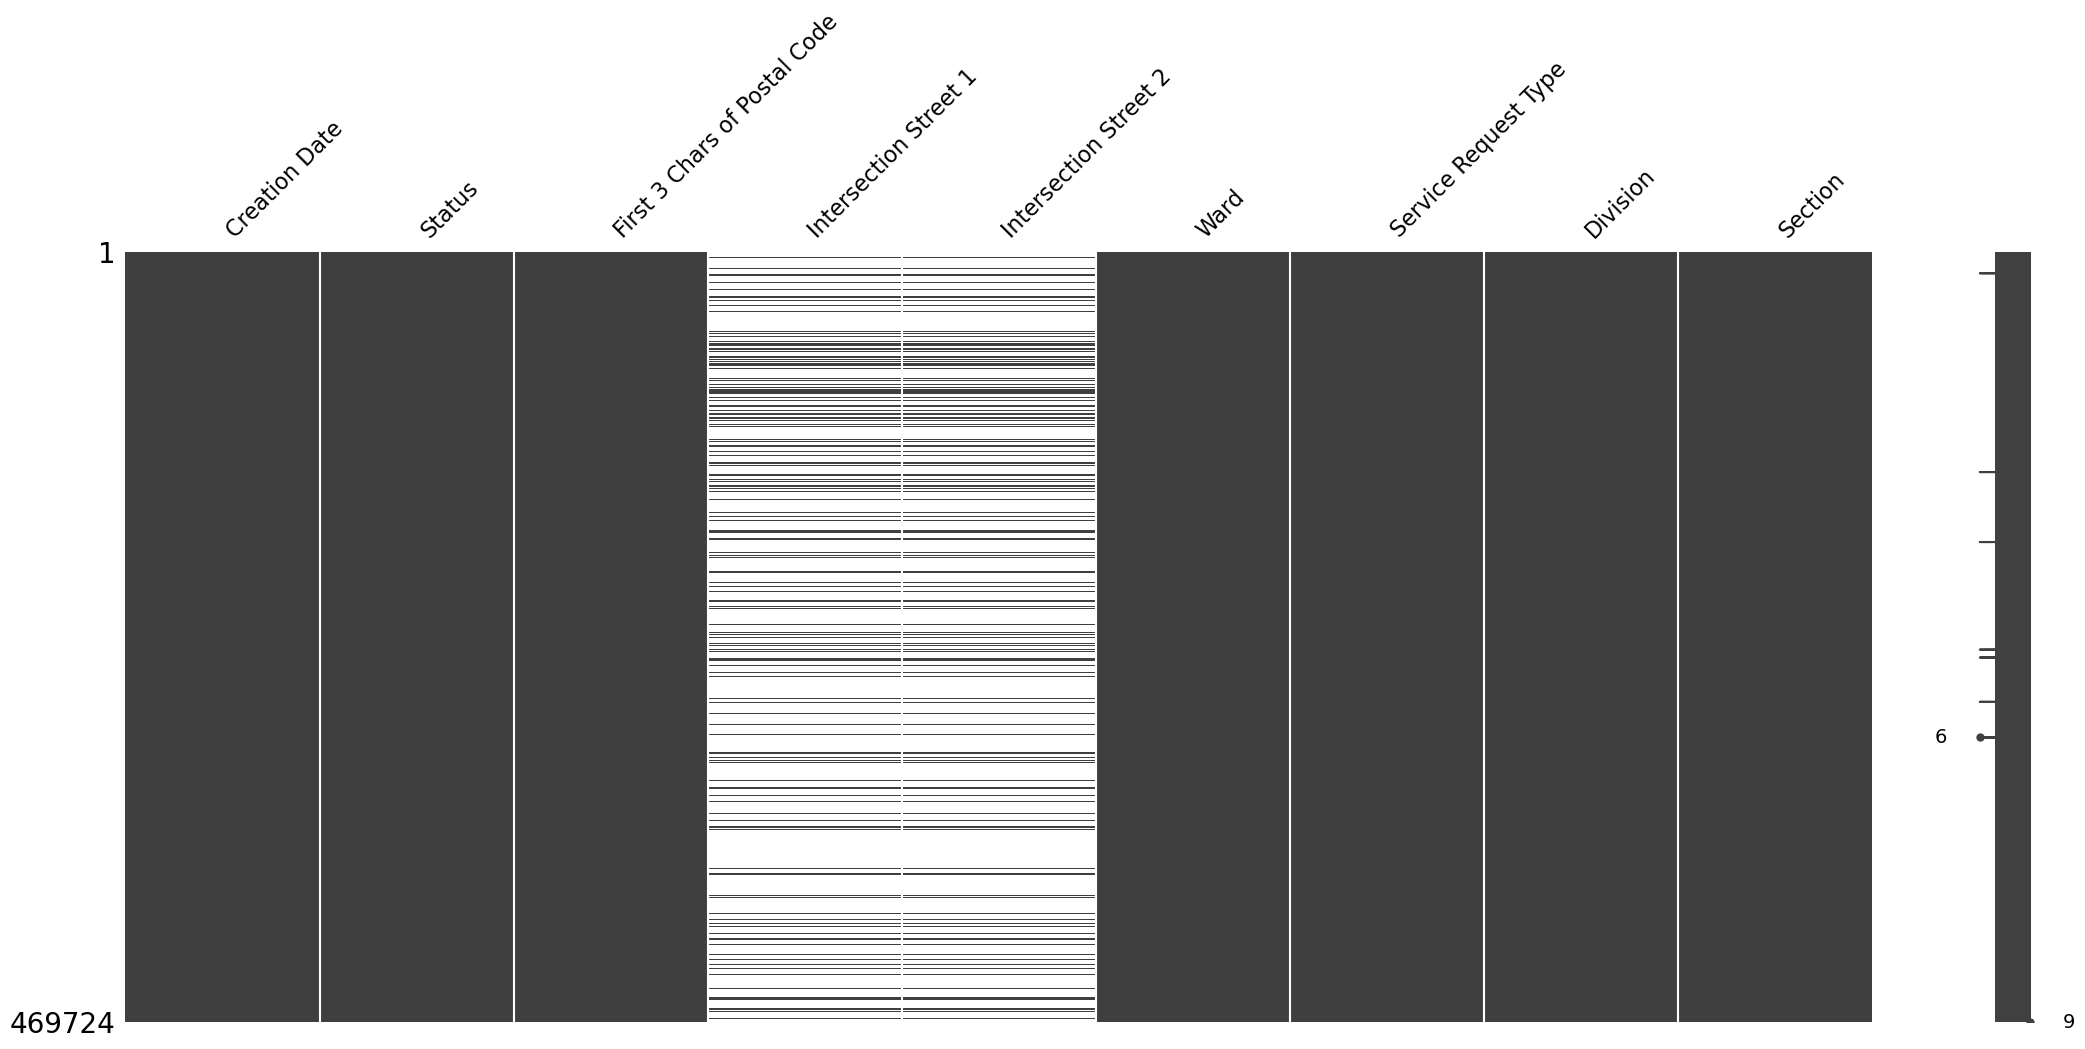

In [5]:
# Identification des valeurs manquantes par missingno
msno.matrix(df)

In [6]:
# Calcule des valeurs manquantes par variable
df.isnull().sum()

Creation Date                        0
Status                               0
First 3 Chars of Postal Code         0
Intersection Street 1           379802
Intersection Street 2           380508
Ward                                 0
Service Request Type                 8
Division                             0
Section                              0
dtype: int64

In [7]:
# Creqtion du copie du dataset pour effectuer les modificqtion
df1 = df
df

,Creation Date,Status,First 3 Chars of Postal Code,Intersection Street 1,Intersection Street 2,Ward,Service Request Type,Division,Section
0,2026-01-01 00:21:51.0000000,Completed,M4L,NaN,NaN,Beaches-East York (19),Stray - Confined,Municipal Licensing & Standards,Toronto Animal Services
1,2026-01-01 00:24:48.0000000,Completed,M1C,NaN,NaN,Scarborough-Rouge Park (25),Property Standards and Maintenance Violations,Municipal Licensing & Standards,Investigation Services
2,2026-01-01 00:27:38.0000000,Completed,Intersection,Leslie St,Finch Ave E,Don Valley North (17),Clean up Debris on Road,Transportation Services,Road Operations
3,2026-01-01 00:29:23.0000000,Completed,M2N,NaN,NaN,Willowdale (18),Sewer Service Line-Blocked,Toronto Water,District Ops
4,2026-01-01 00:32:12.0000000,Closed,Intersection,Lawrence Ave E,Greencrest Crct,Scarborough-Guildwood (24),Traffic Signal Repair,Transportation Services,TMC
...,...,...,...,...,...,...,...,...,...
469719,2026-10-31 23:54:46.0000000,In Progress,M1C,NaN,NaN,Scarborough-Rouge Park (25),Amplified or Musical Instrument Noise,Municipal Licensing & Standards,Bylaw Enforcement
469720,2026-10-31 23:55:35.0000000,In Progress,M4L,NaN,NaN,Beaches-East York (19),Amplified or Musical Instrument Noise,Municipal Licensing & Standards,Bylaw Enforcement
469721,2026-10-31 23:56:27.0000000,New,M5T,NaN,NaN,University-Rosedale (11),Bike Removal and Lost Bike Inquiry,Solid Waste Management Services,Collections
469722,2026-10-31 23:59:19.0000000,Unknown,Intersection,Borden St,College St,University-Rosedale (11),Street Furniture Request,Transportation Services,Road Operations


In [8]:
#calculer des valeur manquqntes par lignes
data_na = df1.isnull().sum()
data_na

Creation Date                        0
Status                               0
First 3 Chars of Postal Code         0
Intersection Street 1           379802
Intersection Street 2           380508
Ward                                 0
Service Request Type                 8
Division                             0
Section                              0
dtype: int64

In [9]:
# Le pourcetage des valeurs manquantes
data_na_p=df1[['Intersection Street 1', 'Intersection Street 2', 'Service Request Type']].isnull().mean()*100
data_na_p

Intersection Street 1    80.856418
Intersection Street 2    81.006719
Service Request Type      0.001703
dtype: float64

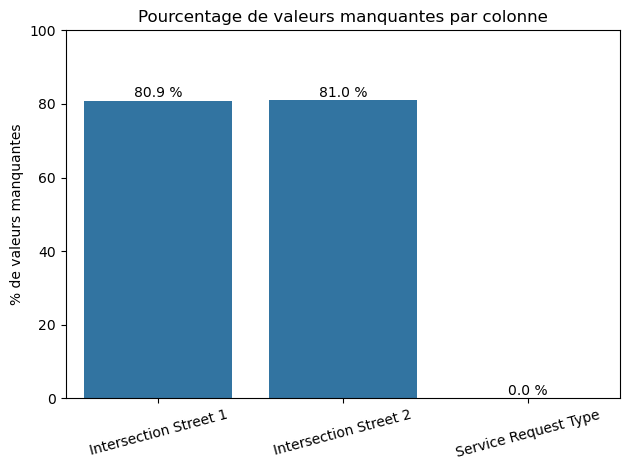

In [10]:
# Diagramme a bar des valeurs manquantes
ax = sns.barplot(x=data_na_p.index, y=data_na_p.values)
ax.set_title("Pourcentage de valeurs manquantes par colonne")
ax.set_ylabel("% de valeurs manquantes")
ax.set_xlabel("")
ax.set_ylim(0, 100)

for i, v in enumerate(data_na_p.values):
    ax.text(i, v + 1, f"{v:.1f} %", ha='center')

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [11]:
# Trie des valeurs manquantes dans les deux variables
df1[(df1['Intersection Street 1'].isnull()) & (df1['Intersection Street 2'].isnull())]

,Creation Date,Status,First 3 Chars of Postal Code,Intersection Street 1,Intersection Street 2,Ward,Service Request Type,Division,Section
0,2026-01-01 00:21:51.0000000,Completed,M4L,NaN,NaN,Beaches-East York (19),Stray - Confined,Municipal Licensing & Standards,Toronto Animal Services
1,2026-01-01 00:24:48.0000000,Completed,M1C,NaN,NaN,Scarborough-Rouge Park (25),Property Standards and Maintenance Violations,Municipal Licensing & Standards,Investigation Services
3,2026-01-01 00:29:23.0000000,Completed,M2N,NaN,NaN,Willowdale (18),Sewer Service Line-Blocked,Toronto Water,District Ops
5,2026-01-01 00:33:42.0000000,Completed,M8Y,NaN,NaN,Etobicoke-Lakeshore (03),Amplified or Musical Instrument Noise,Municipal Licensing & Standards,Bylaw Enforcement
6,2026-01-01 00:34:02.0000000,Completed,M6H,NaN,NaN,Davenport (09),Residential Bin Lid Damaged,Solid Waste Management Services,Collections
...,...,...,...,...,...,...,...,...,...
469716,2026-10-31 23:51:02.0000000,Completed,M5B,NaN,NaN,Toronto Centre (13),Moving Motor Vehicle Noise,Municipal Licensing & Standards,Bylaw Enforcement
469719,2026-10-31 23:54:46.0000000,In Progress,M1C,NaN,NaN,Scarborough-Rouge Park (25),Amplified or Musical Instrument Noise,Municipal Licensing & Standards,Bylaw Enforcement
469720,2026-10-31 23:55:35.0000000,In Progress,M4L,NaN,NaN,Beaches-East York (19),Amplified or Musical Instrument Noise,Municipal Licensing & Standards,Bylaw Enforcement
469721,2026-10-31 23:56:27.0000000,New,M5T,NaN,NaN,University-Rosedale (11),Bike Removal and Lost Bike Inquiry,Solid Waste Management Services,Collections


In [12]:
# Trie des lignes mqnauantes que dans Intersection Street 2
df1[(~df1['Intersection Street 1'].isnull()) & (df1['Intersection Street 2'].isnull())]

,Creation Date,Status,First 3 Chars of Postal Code,Intersection Street 1,Intersection Street 2,Ward,Service Request Type,Division,Section
807,2026-01-02 10:17:54.0000000,Completed,Intersection,Moccasin Trl,NaN,Don Valley East (16),Park Property Snow and Ice Clearing,Parks and Recreation,Parks
3168,2026-01-04 11:17:22.0000000,Completed,Intersection,Cassels Avenue Playground Trl,NaN,Beaches-East York (19),Grass and Sports Field Maintenance in Parks,Parks and Recreation,Parks
5647,2026-01-06 11:57:42.0000000,Completed,Intersection,Traymore Park Trl,NaN,Parkdale-High Park (04),Park Property Snow and Ice Clearing,Parks and Recreation,Parks
6589,2026-01-06 20:25:36.0000000,Completed,Intersection,Kennedy - Margdon Parkette Trl,NaN,Parkdale-High Park (04),Park Graffiti Removal,Parks and Recreation,Parks
6803,2026-01-07 07:34:42.0000000,Completed,Intersection,Dundas St W,NaN,Etobicoke-Lakeshore (03),Road Pothole / Road Damage,Transportation Services,Road Operations
...,...,...,...,...,...,...,...,...,...
468388,2026-10-30 14:50:11.0000000,New,Intersection,Belmont Parkette Trl,NaN,University-Rosedale (11),Investigate Warning Signs,Transportation Services,Traffic Ops
468658,2026-10-30 17:44:48.0000000,Completed,Intersection,Adelaide St E,NaN,Toronto Centre (13),Clean up Litter on Sidewalks and Boulevards,Solid Waste Management Services,Collections
469024,2026-10-31 08:55:41.0000000,Unknown,Intersection,Algonquin Bridge Rd,NaN,Spadina-Fort York (10),Private Transportation Company Complaint,Municipal Licensing & Standards,Business Licensing Enforcement
469034,2026-10-31 09:06:02.0000000,Unknown,Intersection,Algonquin Bridge Rd,NaN,Spadina-Fort York (10),Private Transportation Company Complaint,Municipal Licensing & Standards,Business Licensing Enforcement


In [13]:
# Trie des lignes mqnauantes que dans Intersection Street 1
df1[(df1['Intersection Street 1'].isnull()) & ~(df1['Intersection Street 2'].isnull())]

,Creation Date,Status,First 3 Chars of Postal Code,Intersection Street 1,Intersection Street 2,Ward,Service Request Type,Division,Section


In [14]:
# Croisement intersection1 et ward
df1['Intersection Street 1'].isnull().groupby(df1['Ward']).sum()

Ward
Beaches-East York (19)           21213
Davenport (09)                   22523
Don Valley East (16)              7984
Don Valley North (17)             9839
Don Valley West (15)             15532
Eglinton-Lawrence (08)           19459
Etobicoke Centre (02)            16472
Etobicoke North (01)             11446
Etobicoke-Lakeshore (03)         19317
Humber River-Black Creek (07)     9946
Parkdale-High Park (04)          19302
Scarborough Centre (21)          13444
Scarborough North (23)            8767
Scarborough Southwest (20)       17274
Scarborough-Agincourt (22)        9206
Scarborough-Guildwood (24)       11826
Scarborough-Rouge Park (25)      13824
Spadina-Fort York (10)           13876
Toronto Centre (13)              14389
Toronto-Danforth (14)            23189
Toronto-St. Paul's (12)          18566
University-Rosedale (11)         21514
Unknown                              0
Willowdale (18)                  12232
York Centre (06)                 12856
York South-Weston (0

In [15]:
# Croisement intersection2 et ward
df1['Intersection Street 2'].isnull().groupby(df1['Ward']).sum()

Ward
Beaches-East York (19)           21255
Davenport (09)                   22536
Don Valley East (16)              8009
Don Valley North (17)             9873
Don Valley West (15)             15545
Eglinton-Lawrence (08)           19482
Etobicoke Centre (02)            16483
Etobicoke North (01)             11495
Etobicoke-Lakeshore (03)         19433
Humber River-Black Creek (07)     9950
Parkdale-High Park (04)          19334
Scarborough Centre (21)          13456
Scarborough North (23)            8780
Scarborough Southwest (20)       17287
Scarborough-Agincourt (22)        9211
Scarborough-Guildwood (24)       11838
Scarborough-Rouge Park (25)      13852
Spadina-Fort York (10)           13935
Toronto Centre (13)              14459
Toronto-Danforth (14)            23202
Toronto-St. Paul's (12)          18577
University-Rosedale (11)         21537
Unknown                             10
Willowdale (18)                  12242
York Centre (06)                 12915
York South-Weston (0

**Pour identifier le mécanisme des valeurs manquantes des colonnes Intersection Street 1 et Intersection Street 2, nous avons d’abord mesuré leur ampleur : environ 80 % des observations sont manquantes pour chacune de ces deux variables. Nous avons ensuite croisé ces valeurs manquantes avec la variable Ward, afin de vérifier si elles se concentraient dans certains secteurs. La proportion de valeurs manquantes reste comparable d’un secteur à l’autre. Elles ne semblent donc pas liées à la localisation, ce qui est compatible avec un mécanisme de type MCAR (Missing Completely At Random)** 

In [16]:
# Suppression des variables Intersection Street 1 et Intersection Street 2
df1.drop(columns=['Intersection Street 1', 'Intersection Street 2'], inplace=True)

## Traitement des valeurs manquantes de Service Request Type

In [17]:
# Affichage des lignes
df1[df1['Service Request Type'].isnull()]

,Creation Date,Status,First 3 Chars of Postal Code,Ward,Service Request Type,Division,Section
12966,2026-01-10 10:23:40.0000000,Completed,M1N,Scarborough Southwest (20),NaN,Solid Waste Management Services,Collections and Litter Operations
134249,2026-03-23 10:04:30.0000000,Completed,M3J,Humber River-Black Creek (07),NaN,Solid Waste Management Services,Collections and Litter Operations
176929,2026-04-22 10:16:23.0000000,Completed,M6C,Toronto-St. Paul's (12),NaN,Solid Waste Management Services,Collections and Litter Operations
242569,2026-06-03 12:35:40.0000000,Completed,M6N,York South-Weston (05),NaN,Solid Waste Management Services,Collections and Litter Operations
247389,2026-06-05 17:18:36.0000000,Completed,M5A,Toronto Centre (13),NaN,Solid Waste Management Services,Collections and Litter Operations
254217,2026-06-09 23:14:53.0000000,Completed,Intersection,Scarborough North (23),NaN,Solid Waste Management Services,Collections and Litter Operations
274418,2026-06-21 17:00:47.0000000,Completed,M4P,Don Valley West (15),NaN,Solid Waste Management Services,Collections and Litter Operations
296128,2026-07-05 18:20:06.0000000,Completed,M6C,Toronto-St. Paul's (12),NaN,Solid Waste Management Services,Collections and Litter Operations


**Nous avons opté pour les suppressions de ces lignes étant donnée qu'elle ne représente que 0.002146% de notre jeu de données**

In [18]:
# Suppression des lignes où Service Request Type est manquant
df1.dropna(subset=['Service Request Type'], inplace=True)

In [19]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 469716 entries, 0 to 469723
Data columns (total 7 columns):
 #   Column                        Non-Null Count   Dtype 
---  ------                        --------------   ----- 
 0   Creation Date                 469716 non-null  object
 1   Status                        469716 non-null  object
 2   First 3 Chars of Postal Code  469716 non-null  object
 3   Ward                          469716 non-null  object
 4   Service Request Type          469716 non-null  object
 5   Division                      469716 non-null  object
 6   Section                       469716 non-null  object
dtypes: object(7)
memory usage: 28.7+ MB


# Traitement des doublons

In [20]:
# Detection des doublons
df1.duplicated().sum()

np.int64(218)

In [21]:
#Afficher les lignes en doublons
df1[df1.duplicated(keep=False)]

,Creation Date,Status,First 3 Chars of Postal Code,Ward,Service Request Type,Division,Section
10189,2026-01-08 17:26:45.0000000,Completed,M1R,Scarborough Centre (21),Residential Furniture / Not Picked Up,Solid Waste Management Services,Collections
10190,2026-01-08 17:26:45.0000000,Completed,M1R,Scarborough Centre (21),Residential Furniture / Not Picked Up,Solid Waste Management Services,Collections
42673,2026-01-26 18:39:11.0000000,Completed,M1C,Scarborough-Rouge Park (25),Driveway Blocked By Plowed Snowbank,Transportation Services,Road Operations
42674,2026-01-26 18:39:11.0000000,Completed,M1C,Scarborough-Rouge Park (25),Driveway Blocked By Plowed Snowbank,Transportation Services,Road Operations
46424,2026-01-27 15:59:49.0000000,Completed,Intersection,Toronto-St. Paul's (12),School Zone Snow Clearing,Transportation Services,Road Operations
...,...,...,...,...,...,...,...
452554,2026-10-18 05:51:46.0000000,Completed,M4E,Beaches-East York (19),Pick up Dead Wildlife,Municipal Licensing & Standards,Toronto Animal Services
454776,2026-10-19 23:08:29.0000000,Completed,M8Z,Etobicoke-Lakeshore (03),Coyote Dangerous to Public Safety,Municipal Licensing & Standards,Toronto Animal Services
454777,2026-10-19 23:08:29.0000000,Completed,M8Z,Etobicoke-Lakeshore (03),Coyote Dangerous to Public Safety,Municipal Licensing & Standards,Toronto Animal Services
460209,2026-10-23 15:00:18.0000000,Completed,M1B,Scarborough North (23),Feeding Wildlife on Private and Public Property,Municipal Licensing & Standards,District Enforcement


In [22]:
doublons = df1.duplicated().mean()*100
doublons

np.float64(0.04641102283081692)

**Nous avons dans notre dataset 3410 lignes dupliqués, ce qui représente une 0.9% de notre dataset, nous avons opté pour la suppression de ces lignes étant donnée quel peuvent ajouter un poids en plus par rapport au demande, divison ou section pour éviter de fausser nos analyse la suppression est la meilleur option.**

In [23]:
# Suppression des doublons
df1.drop_duplicates(inplace=True)

In [24]:
# vérification
df1.duplicated().sum()

np.int64(0)

# **Correction des types et les incohérences**

## Conversion de la variable Creation date en Datetime

In [25]:
import numpy as np

# Aperçu du format brut
df1['Creation Date'].head(10)

0    2026-01-01 00:21:51.0000000
1    2026-01-01 00:24:48.0000000
2    2026-01-01 00:27:38.0000000
3    2026-01-01 00:29:23.0000000
4    2026-01-01 00:32:12.0000000
5    2026-01-01 00:33:42.0000000
6    2026-01-01 00:34:02.0000000
7    2026-01-01 00:45:00.0000000
8    2026-01-01 00:58:49.0000000
9    2026-01-01 01:00:05.0000000
Name: Creation Date, dtype: object

**Comme l'on peut le voir nous avons des dates en format object, nous allons les convertir en date et vérifier que nous n'avons de problème avec les dates.**

In [26]:
# création d'une variable test de date
date = pd.to_datetime(df1['Creation Date'], errors='coerce', yearfirst=True)

In [27]:
# Vérification des valeurs manquantes après modifications
date.isna().sum()

np.int64(0)

In [28]:
# vérification du type
date.info()

<class 'pandas.core.series.Series'>
Index: 469498 entries, 0 to 469723
Series name: Creation Date
Non-Null Count   Dtype         
--------------   -----         
469498 non-null  datetime64[ns]
dtypes: datetime64[ns](1)
memory usage: 7.2 MB


**Comme l'on peut le voir, nous avons aucune valeur manquantes après la convertion vers le format datetime, nous povons confirmer que nous 
n'avons aucune problème de les date**

In [29]:
# modification depuis la variable df1
df1['Creation Date'] = pd.to_datetime(df1['Creation Date'], errors='coerce', yearfirst=True)

In [30]:
#vérification 
df1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 469498 entries, 0 to 469723
Data columns (total 7 columns):
 #   Column                        Non-Null Count   Dtype         
---  ------                        --------------   -----         
 0   Creation Date                 469498 non-null  datetime64[ns]
 1   Status                        469498 non-null  object        
 2   First 3 Chars of Postal Code  469498 non-null  object        
 3   Ward                          469498 non-null  object        
 4   Service Request Type          469498 non-null  object        
 5   Division                      469498 non-null  object        
 6   Section                       469498 non-null  object        
dtypes: datetime64[ns](1), object(6)
memory usage: 28.7+ MB


## Nettoyage des espaces et standardisation des libellés

In [31]:
df1

,Creation Date,Status,First 3 Chars of Postal Code,Ward,Service Request Type,Division,Section
0,2026-01-01 00:21:51,Completed,M4L,Beaches-East York (19),Stray - Confined,Municipal Licensing & Standards,Toronto Animal Services
1,2026-01-01 00:24:48,Completed,M1C,Scarborough-Rouge Park (25),Property Standards and Maintenance Violations,Municipal Licensing & Standards,Investigation Services
2,2026-01-01 00:27:38,Completed,Intersection,Don Valley North (17),Clean up Debris on Road,Transportation Services,Road Operations
3,2026-01-01 00:29:23,Completed,M2N,Willowdale (18),Sewer Service Line-Blocked,Toronto Water,District Ops
4,2026-01-01 00:32:12,Closed,Intersection,Scarborough-Guildwood (24),Traffic Signal Repair,Transportation Services,TMC
...,...,...,...,...,...,...,...
469719,2026-10-31 23:54:46,In Progress,M1C,Scarborough-Rouge Park (25),Amplified or Musical Instrument Noise,Municipal Licensing & Standards,Bylaw Enforcement
469720,2026-10-31 23:55:35,In Progress,M4L,Beaches-East York (19),Amplified or Musical Instrument Noise,Municipal Licensing & Standards,Bylaw Enforcement
469721,2026-10-31 23:56:27,New,M5T,University-Rosedale (11),Bike Removal and Lost Bike Inquiry,Solid Waste Management Services,Collections
469722,2026-10-31 23:59:19,Unknown,Intersection,University-Rosedale (11),Street Furniture Request,Transportation Services,Road Operations


In [32]:
# Modalités avec des espaces en trop avant nettoyage
cols_texte = df1.select_dtypes(include=['object', 'string']).columns
for col in cols_texte:
    n = (df1[col].dropna() != df1[col].dropna().str.strip()).sum()
    print(f"{col} : {n} valeurs avec espaces en début/fin")

Status : 0 valeurs avec espaces en début/fin
First 3 Chars of Postal Code : 0 valeurs avec espaces en début/fin
Ward : 0 valeurs avec espaces en début/fin
Service Request Type : 0 valeurs avec espaces en début/fin
Division : 0 valeurs avec espaces en début/fin
Section : 0 valeurs avec espaces en début/fin


In [33]:
# Modalités avec des espaces en trop avant nettoyage
cols_texte = df1.select_dtypes(include=['object', 'string']).columns
for col in cols_texte:
    n = (df1[col].dropna() != df1[col].dropna().str.strip()).sum()
    print(f"{col} : {n} valeurs avec espaces en début/fin")

Status : 0 valeurs avec espaces en début/fin
First 3 Chars of Postal Code : 0 valeurs avec espaces en début/fin
Ward : 0 valeurs avec espaces en début/fin
Service Request Type : 0 valeurs avec espaces en début/fin
Division : 0 valeurs avec espaces en début/fin
Section : 0 valeurs avec espaces en début/fin


In [34]:
# Vérification des modalités de toutes les variables
print(df1['Status'].unique(), df1['Ward'].unique())

['Completed' 'Closed' 'In Progress' 'New' 'Cancelled' 'Unknown'] ['Beaches-East York (19)' 'Scarborough-Rouge Park (25)'
 'Don Valley North (17)' 'Willowdale (18)' 'Scarborough-Guildwood (24)'
 'Etobicoke-Lakeshore (03)' 'Davenport (09)' 'Don Valley East (16)'
 'Scarborough Centre (21)' 'York South-Weston (05)' 'Toronto Centre (13)'
 'Etobicoke Centre (02)' 'Spadina-Fort York (10)'
 'Scarborough Southwest (20)' 'Toronto-Danforth (14)'
 'Scarborough North (23)' 'Parkdale-High Park (04)'
 'Scarborough-Agincourt (22)' 'Eglinton-Lawrence (08)' 'York Centre (06)'
 'University-Rosedale (11)' 'Humber River-Black Creek (07)'
 "Toronto-St. Paul's (12)" 'Etobicoke North (01)' 'Don Valley West (15)'
 'Unknown']


In [35]:
# Harmonisation des variantes d'orthographe dans Status
df1['Status'] = df1['Status'].replace({'Canceled': 'Cancelled'})
df1['Status'].value_counts()

Status
Completed      352697
Cancelled       44115
In Progress     34665
New             22047
Closed           9210
Unknown          6764
Name: count, dtype: int64

## Contrôle des modalités rares

In [36]:
def modalites_rares(serie, seuil=0.5):
    """Retourne les modalités qui représentent moins de `seuil` % des lignes."""
    pct = serie.value_counts(normalize=True) * 100
    return pct[pct < seuil].round(3)

print("Status - modalités rares :")
print(modalites_rares(df1['Status']))

Status - modalités rares :
Series([], Name: proportion, dtype: float64)


In [37]:
print("Nombre de Ward :", df1['Ward'].nunique())
print("\nWard - modalités rares :")
print(modalites_rares(df1['Ward']))
print("\nLignes avec Ward = 'Unknown' :", (df1['Ward'] == 'Unknown').sum())

Nombre de Ward : 26

Ward - modalités rares :
Ward
Unknown    0.003
Name: proportion, dtype: float64

Lignes avec Ward = 'Unknown' : 13


# **Calculer les statistiques descriptives des requêtes**

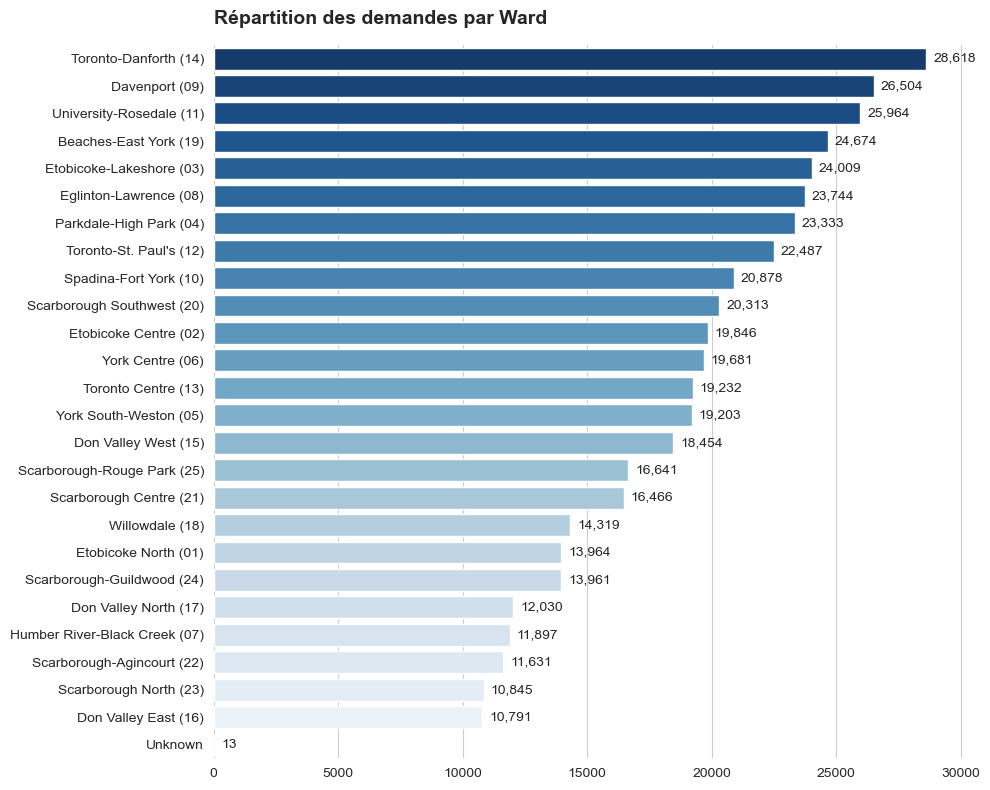

In [38]:
# Préparer les données triées
counts = df1['Ward'].value_counts().reset_index()
counts.columns = ['Ward', 'Demandes']

plt.figure(figsize=(10, 8))
sns.set_style("whitegrid")

ax = sns.barplot(
    data=counts, 
    x='Demandes', 
    y='Ward', 
    palette='Blues_r',  # Dégradé du plus foncé au plus clair
    hue='Ward', 
    legend=False
)

# Ajouter les chiffres au bout des barres
for container in ax.containers:
    ax.bar_label(container, padding=5, fontsize=10, fmt='{:,.0f}')

sns.despine(left=True, bottom=True)
plt.xlabel("")
plt.ylabel("")
plt.title("Répartition des demandes par Ward", fontsize=14, fontweight='bold', loc='left', pad=15)
plt.tight_layout()
plt.show()

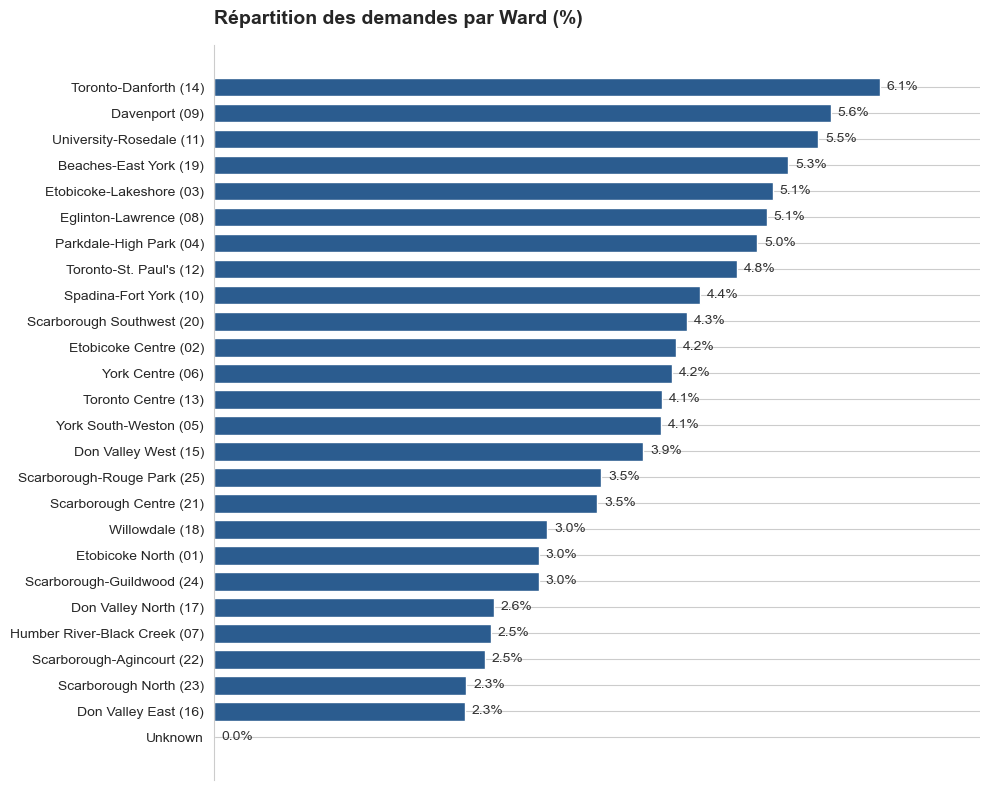

In [39]:
import matplotlib.pyplot as plt

# 1. Calculer les pourcentages et trier pour avoir le plus grand en haut
pcts = (df1['Ward'].value_counts(normalize=True) * 100).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 8))

# 2. Tracer les barres
bars = ax.barh(pcts.index, pcts.values, color='#2b5c8f', height=0.7)

# 3. Ajouter les pourcentages au bout des barres (ex: 14.5%)
ax.bar_label(bars, padding=5, fontsize=10, color='#333333', fmt='%.1f%%')

# 4. Épurer le graphique et ajuster la marge droite pour que le texte ne soit pas coupé
ax.set_xlim(0, pcts.max() * 1.15)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.xaxis.set_visible(False)

# 5. Titre clair
ax.set_title("Répartition des demandes par Ward (%)", fontsize=14, fontweight='bold', loc='left', pad=15)

plt.tight_layout()
plt.show()

In [40]:
## Analyse des demandes par division
df1['Division'].value_counts()

Division
Transportation Services            155769
Solid Waste Management Services    112829
Municipal Licensing & Standards    110677
Environment, Climate & Forestry     40578
Toronto Water                       38014
Parks and Recreation                 7982
311                                  3649
Name: count, dtype: int64

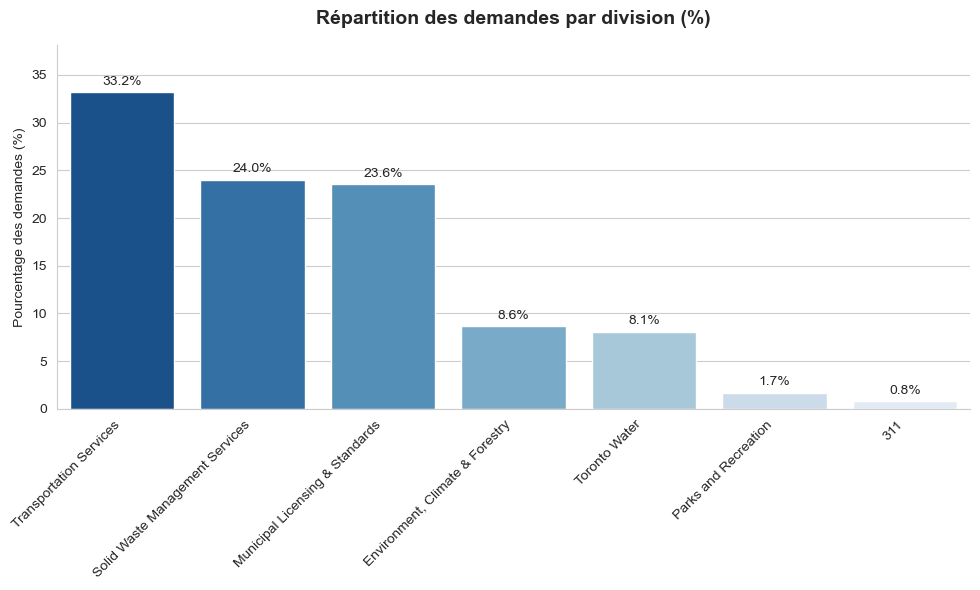

In [41]:
# 1. Calculer les pourcentages pour chaque division
pcts = (df1['Division'].value_counts(normalize=True) * 100).reset_index()
pcts.columns = ['Division', 'Pourcentage']

# 2. Tracer le graphique
plt.figure(figsize=(10, 6))
ax = sns.barplot(data=pcts, x='Division', y='Pourcentage', hue='Division', palette='Blues_r', legend=False)

# 3. Ajouter les pourcentages au-dessus des barres
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3, fontsize=10)

# 4. Mise en forme et titres
ax.set_title("Répartition des demandes par division (%)", fontsize=14, fontweight='bold', pad=15)
ax.set_ylabel("Pourcentage des demandes (%)")
ax.set_xlabel("")
ax.set_ylim(0, pcts['Pourcentage'].max() * 1.15)  # Espace en haut pour ne pas couper les chiffres
sns.despine()

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## Pour mieux nous permettre de comprendre 
Voici le le role de chaque division :

**1. Transportation Services (155 769), environ 33 % des demandes**

Elle gère et entretient le réseau routier de la ville : les chaussées, les trottoirs, la signalisation, les feux de circulation et le déneigement.

**2. Solid Waste Management Services (112 829), environ 24% des demandes**

Elle s'occupe de la collecte et de l'élimination des déchets : ordures, recyclage, bac vert (compost) et gros objets.

**3. Municipal Licensing & Standards (110 677), environ 23% des demandes**

Elle fait respecter les règlements municipaux (les bylaws) et s'occupe des animaux.

**4. Environment, Climate & Forestry (40 578), environ 9% des demande**

Elle gère les arbres de la ville et l'environnement naturel.

**5. Toronto Water (38 014), environ 8% des demandes**  

Elle s'occupe de l'eau potable, des égouts et du drainage.

**6. Parks and Recreation (7 982), environ 2% des demandes**

Elle entretient les parcs et les installations de loisirs.

**7. 311 (3 649), environ 1% des demandes**

C'est le centre d'appels lui-même. Il ne fait pas d'intervention sur le terrain : il traite des demandes administratives.

# Analyser les statuts de traitement (Status) par division

In [42]:
# Vérification du Status en fonction du service
df1['Division'].groupby(df1['Status']).count()

Status
Cancelled       44115
Closed           9210
Completed      352697
In Progress     34665
New             22047
Unknown          6764
Name: Division, dtype: int64

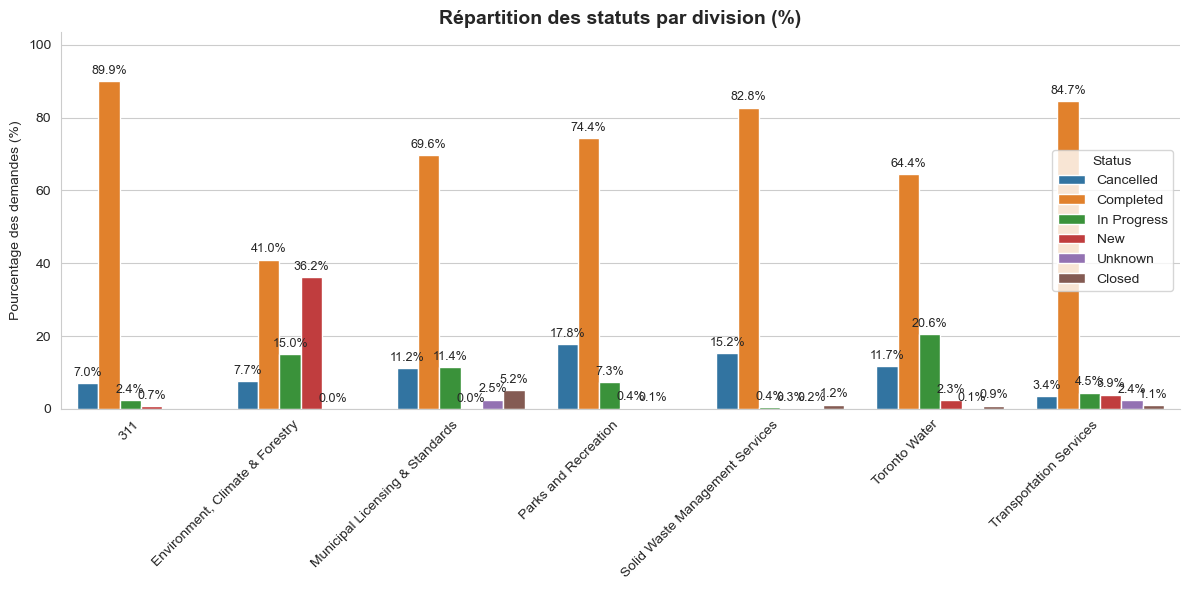

In [43]:
df_status = df1.groupby(['Division', 'Status']).size().reset_index(name='Nombre_demandes')

# 2. Calculer le pourcentage au sein de chaque division (total = 100 % par division)
df_status['Pourcentage'] = (
    df_status['Nombre_demandes'] / df_status.groupby('Division')['Nombre_demandes'].transform('sum') * 100
)

# 3. Tracer le graphique avec les pourcentages
plt.figure(figsize=(12, 6))
ax = sns.barplot(data=df_status, x='Division', y='Pourcentage', hue='Status')

# 4. Ajouter les pourcentages au-dessus de chaque barre
for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=9, fmt='%.1f%%')

# 5. Mise en forme et espace en haut pour ne pas couper les étiquettes
ax.set_ylim(0, df_status['Pourcentage'].max() * 1.15)
ax.set_title("Répartition des statuts par division (%)", fontsize=14, fontweight='bold')
ax.set_ylabel("Pourcentage des demandes (%)")
ax.set_xlabel("")
sns.despine()

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [44]:
# Donne un DataFrame propre prêt pour un graphique
df_status = df1.groupby(['Division', 'Status']).size().reset_index(name='Nombre_demandes')
print(df_status)

                           Division       Status  Nombre_demandes
0                               311    Cancelled              255
1                               311    Completed             3282
2                               311  In Progress               87
3                               311          New               25
4   Environment, Climate & Forestry    Cancelled             3129
5   Environment, Climate & Forestry    Completed            16640
6   Environment, Climate & Forestry  In Progress             6101
7   Environment, Climate & Forestry          New            14690
8   Environment, Climate & Forestry      Unknown               18
9   Municipal Licensing & Standards    Cancelled            12374
10  Municipal Licensing & Standards       Closed             5784
11  Municipal Licensing & Standards    Completed            77068
12  Municipal Licensing & Standards  In Progress            12644
13  Municipal Licensing & Standards          New                5
14  Munici